In [13]:
# วิเคราะห์ข้อมูลสุขภาพจิต (Mental_cleaned.csv)
#1. ตั้งค่า อ่านข้อมูล และแยกประเทศ / กลุ่มรวม
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

BASE = r"C:\Users\LENOVO\OneDrive - BUU\Desktop"
INPUT_FILE = os.path.join(BASE, "Data", "processed", "Mental_cleaned.csv")
RESULTS = os.path.join(BASE, "Results")
os.makedirs(RESULTS, exist_ok=True)

In [14]:

# ฟอนต์ไทยสำหรับกราฟ (ถ้าไม่มี TH Sarabun PSK จะใช้ตัวสำรอง)

available = {f.name for f in font_manager.fontManager.ttflist}
chosen_font = "DejaVu Sans"
for name in ["TH Sarabun PSK", "Tahoma", "Leelawadee UI"]:
    if name in available:
        chosen_font = name
        break
plt.rcParams["font.family"] = chosen_font
plt.rcParams["font.size"] = 16 if chosen_font == "TH Sarabun PSK" else 11
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# ---- สไตล์กราฟกลาง (ใช้ร่วมกันทุกกราฟ) ----
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
DASH = (0, (5, 3))
BASE_FONT = plt.rcParams["font.size"]


def style_axes(ax, grid_axis="y"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0, labelsize=BASE_FONT)


def add_title(ax, title, subtitle=None):
    ax.set_title(title, loc="left", fontsize=BASE_FONT + 5, fontweight="bold",
                 color=INK, pad=38 if subtitle else 14)
    if subtitle:
        ax.text(0, 1.035, subtitle, transform=ax.transAxes, color=INK2,
                fontsize=BASE_FONT + 1)

df = pd.read_csv(INPUT_FILE, keep_default_na=False)

DISEASES = {
    "Schizophrenia_pct": "จิตเภท",
    "Depressive_pct": "ซึมเศร้า",
    "Anxiety_pct": "วิตกกังวล",
    "Bipolar_pct": "ไบโพลาร์",
    "Eating_pct": "การกินผิดปกติ",
}
cols = list(DISEASES)
FIRST_YEAR, LAST_YEAR = df["Year"].min(), df["Year"].max()

countries = df[df["Entity_type"] == "Country"].copy()   # เฉพาะประเทศ
latest = countries[countries["Year"] == LAST_YEAR]
print("ประเทศ:", countries["Entity"].nunique(), "| ปี:", FIRST_YEAR, "-", LAST_YEAR)


def save_fig(name):
    path = os.path.join(RESULTS, name)
    plt.savefig(path, dpi=200, bbox_inches="tight")
    print("บันทึกกราฟ:", path)

ประเทศ: 204 | ปี: 1990 - 2019


                             โรค    mean  median     std     min     max      Q1      Q3     IQR      CV
Schizophrenia_pct         จิตเภท  0.2659  0.2728  0.0393  0.1884  0.4620  0.2417  0.2857  0.0440  0.1479
Depressive_pct          ซึมเศร้า  3.7674  3.6507  0.9417  1.5223  7.6459  3.0615  4.3720  1.3105  0.2500
Anxiety_pct            วิตกกังวล  4.1002  3.9423  1.0630  1.8800  8.6246  3.4245  4.5445  1.1200  0.2593
Bipolar_pct             ไบโพลาร์  0.6391  0.5793  0.2358  0.1817  1.5067  0.5213  0.8575  0.3362  0.3690
Eating_pct         การกินผิดปกติ  0.1951  0.1438  0.1394  0.0448  1.0317  0.0957  0.2437  0.1481  0.7142
บันทึกกราฟ: C:\Users\LENOVO\OneDrive - BUU\Desktop\Results\q1_mean_by_disease.png


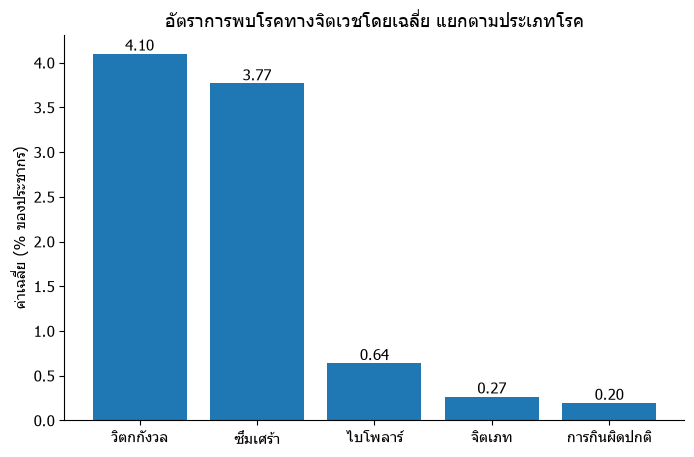

In [15]:
#2. ข้อ 1: โรคไหนมีอัตราพบสูงสุดโดยเฉลี่ย (สถิติพรรณนา + กราฟแท่ง)
desc = countries[cols].agg(["mean", "median", "std", "min", "max"]).T
desc["Q1"] = countries[cols].quantile(0.25)
desc["Q3"] = countries[cols].quantile(0.75)
desc["IQR"] = desc["Q3"] - desc["Q1"]
desc["CV"] = desc["std"] / desc["mean"]      # ใช้เทียบความกระจายข้ามโรค
desc.insert(0, "โรค", [DISEASES[c] for c in desc.index])
desc = desc.round(4)
print(desc.to_string())
desc.to_csv(os.path.join(RESULTS, "q1_descriptive_stats.csv"),
            encoding="utf-8-sig")

order = desc.sort_values("mean", ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(order["โรค"], order["mean"])
ax.bar_label(bars, fmt="%.2f")
ax.set_ylabel("ค่าเฉลี่ย (% ของประชากร)")
ax.set_title("อัตราการพบโรคทางจิตเวชโดยเฉลี่ย แยกตามประเภทโรค")
save_fig("q1_mean_by_disease.png")
plt.show()

อันดับ 1 ของแต่ละโรค (ปี 2019 ):
          โรค   เกณฑ์  อันดับ        ประเทศ  ค่า(%)
       จิตเภท ปี 2019       1 United States  0.4336
     ซึมเศร้า ปี 2019       1        Uganda  6.5845
    วิตกกังวล ปี 2019       1      Portugal  8.0276
     ไบโพลาร์ ปี 2019       1   New Zealand  1.5064
การกินผิดปกติ ปี 2019       1     Australia  1.0317
บันทึกกราฟ: C:\Users\LENOVO\OneDrive - BUU\Desktop\Results\q2_top10_countries.png


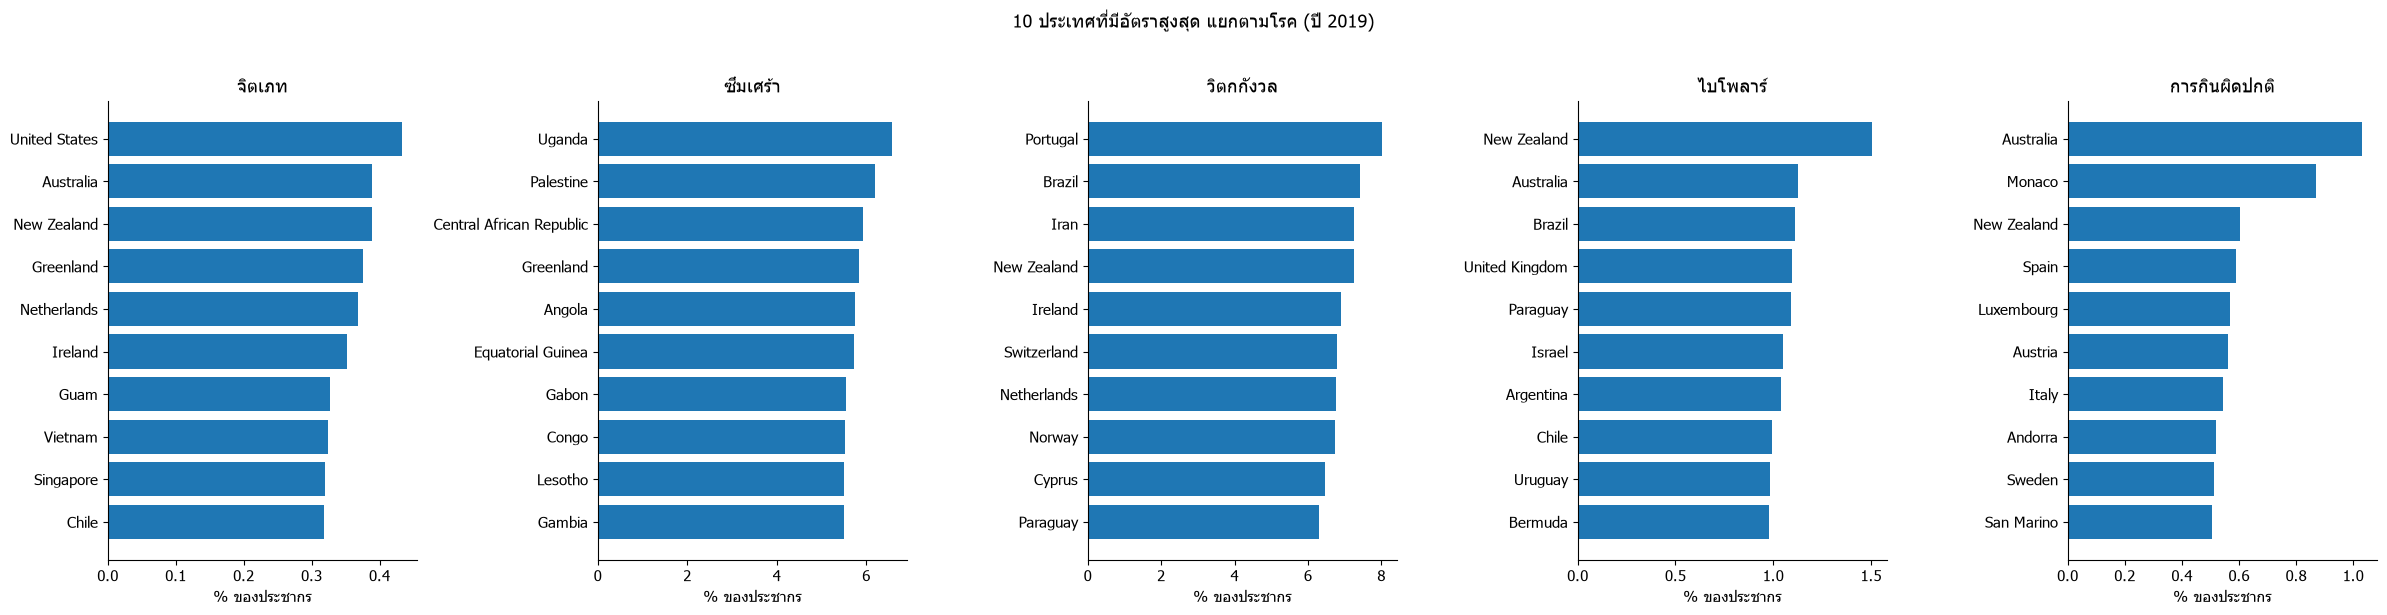

In [16]:
#3. ข้อ 2: ประเทศไหนมีอัตราสูงสุด (อันดับ Top 10)
avg_all = countries.groupby("Entity")[cols].mean()   # เฉลี่ยทุกปี 1990-2019

rank_rows = []
for c in cols:
    for label, series in [(f"ปี {LAST_YEAR}", latest.set_index("Entity")[c]),
                          (f"เฉลี่ย {FIRST_YEAR}-{LAST_YEAR}", avg_all[c])]:
        top = series.nlargest(10)
        for i, (ent, val) in enumerate(top.items(), start=1):
            rank_rows.append({"โรค": DISEASES[c], "เกณฑ์": label,
                              "อันดับ": i, "ประเทศ": ent, "ค่า(%)": round(val, 4)})
ranking = pd.DataFrame(rank_rows)
ranking.to_csv(os.path.join(RESULTS, "q2_top10_countries.csv"),
               index=False, encoding="utf-8-sig")

print("อันดับ 1 ของแต่ละโรค (ปี", LAST_YEAR, "):")
print(ranking[(ranking["อันดับ"] == 1) & (ranking["เกณฑ์"] == f"ปี {LAST_YEAR}")]
      .to_string(index=False))

fig, axes = plt.subplots(1, 5, figsize=(24, 6))
for ax, c in zip(axes, cols):
    top = latest.nlargest(10, c)[["Entity", c]].iloc[::-1]
    ax.barh(top["Entity"], top[c])
    ax.set_title(DISEASES[c])
    ax.set_xlabel("% ของประชากร")
fig.suptitle(f"10 ประเทศที่มีอัตราสูงสุด แยกตามโรค (ปี {LAST_YEAR})", y=1.02)
plt.tight_layout()
save_fig("q2_top10_countries.png")
plt.show()

บันทึกกราฟ: C:\Users\LENOVO\OneDrive - BUU\Desktop\Results\q3_boxplot_by_disease.png


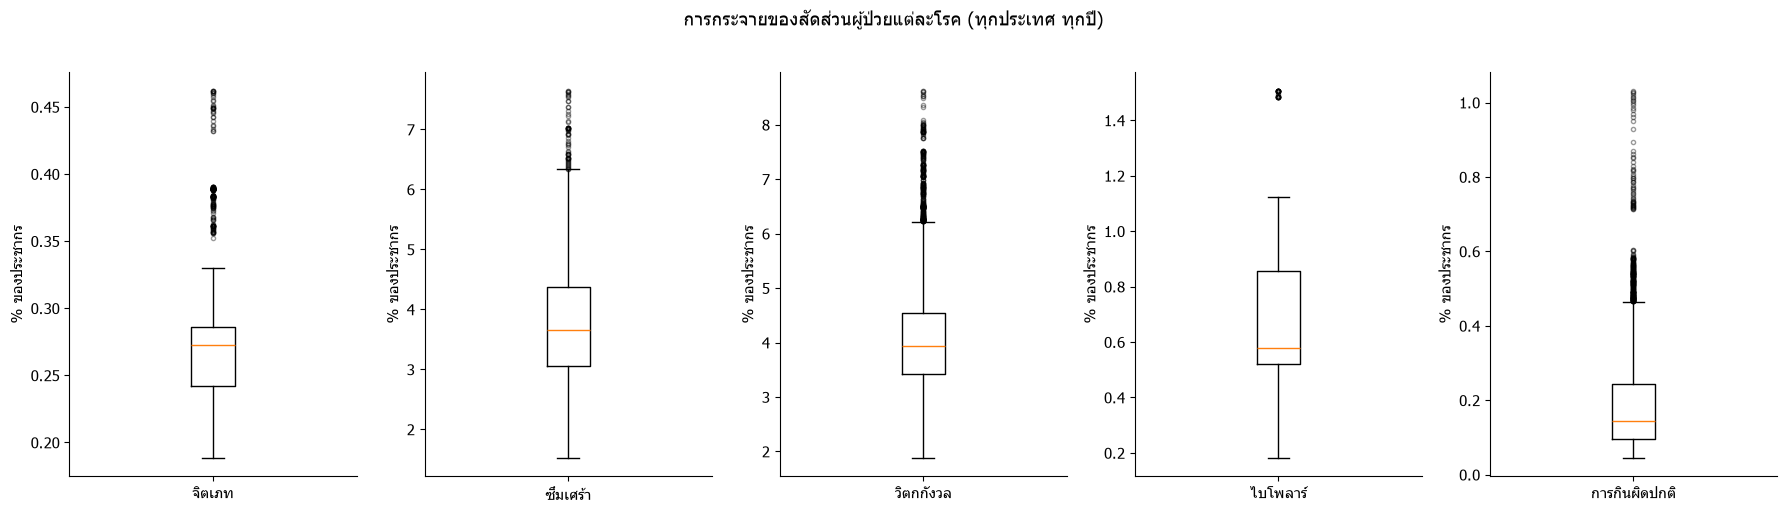

In [17]:
#4. ข้อ 3: สัดส่วนผู้ป่วยแต่ละโรคแตกต่างกันอย่างไร (Boxplot)
# แยกช่องย่อยต่อโรค เพราะระดับค่าต่างกันมาก ถ้ารวมแกนเดียวโรคค่าต่ำจะแบน
fig, axes = plt.subplots(1, 5, figsize=(18, 5))
for ax, c in zip(axes, cols):
    ax.boxplot(countries[c], showfliers=True,
               flierprops={"markersize": 3, "alpha": 0.4})
    ax.set_xticks([1])
    ax.set_xticklabels([DISEASES[c]])
    ax.set_ylabel("% ของประชากร")
fig.suptitle("การกระจายของสัดส่วนผู้ป่วยแต่ละโรค (ทุกประเทศ ทุกปี)", y=1.02)
plt.tight_layout()
save_fig("q3_boxplot_by_disease.png")
plt.show()

          โรค  ค่าปี 1990  ค่าปี 2019  % เปลี่ยนแปลง  ความชัน (จุด%/ปี)
การกินผิดปกติ      0.1505      0.1740          15.56            0.00086
     ไบโพลาร์      0.4901      0.4898          -0.05           -0.00000
    วิตกกังวล      3.7916      3.7795          -0.32           -0.00061
       จิตเภท      0.2899      0.2874          -0.87           -0.00007
     ซึมเศร้า      3.4862      3.4401          -1.32           -0.00639
บันทึกกราฟ: C:\Users\LENOVO\OneDrive - BUU\Desktop\Results\trend_world_index.png


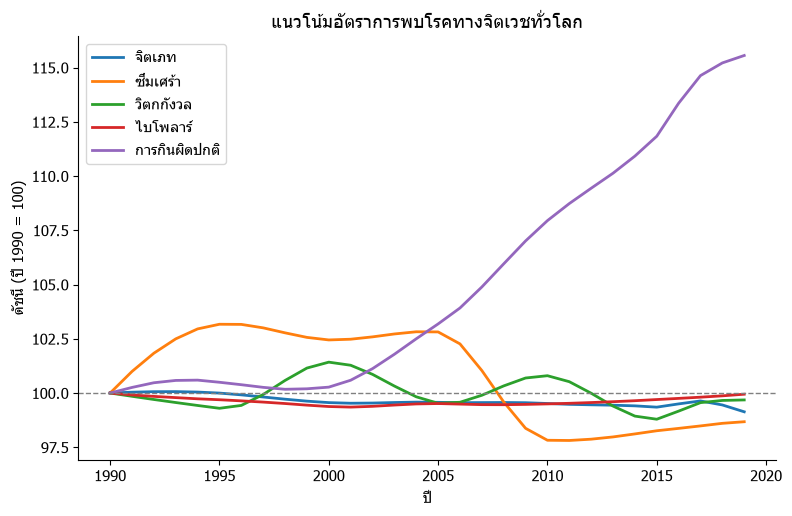

In [18]:
# 5. กิมมิค 1: แนวโน้ม 1990-2019 (ใช้ค่าประมาณระดับโลก "World")
world = df[df["Entity"] == "World"].sort_values("Year")
trend_rows = []
for c in cols:
    first, last = world[c].iloc[0], world[c].iloc[-1]
    slope = np.polyfit(world["Year"], world[c], 1)[0]   # ความชันเส้นตรง
    trend_rows.append({"โรค": DISEASES[c],
                       f"ค่าปี {FIRST_YEAR}": round(first, 4),
                       f"ค่าปี {LAST_YEAR}": round(last, 4),
                       "% เปลี่ยนแปลง": round((last - first) / first * 100, 2),
                       "ความชัน (จุด%/ปี)": round(slope, 5)})
trend = pd.DataFrame(trend_rows).sort_values("% เปลี่ยนแปลง", ascending=False)
print(trend.to_string(index=False))
trend.to_csv(os.path.join(RESULTS, "trend_1990_2019.csv"),
             index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(9, 5.5))
for c in cols:
    ax.plot(world["Year"], world[c] / world[c].iloc[0] * 100,
            label=DISEASES[c], linewidth=2)
ax.axhline(100, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("ปี")
ax.set_ylabel(f"ดัชนี (ปี {FIRST_YEAR} = 100)")
ax.set_title("แนวโน้มอัตราการพบโรคทางจิตเวชทั่วโลก")
ax.legend()
save_fig("trend_world_index.png")
plt.show()

ค่าตามกลุ่มรายได้ ปี 2019 (% ของประชากร)
          จิตเภท  ซึมเศร้า  วิตกกังวล  ไบโพลาร์  การกินผิดปกติ
สูง       0.3270    3.6411     4.8859    0.7385         0.4167
กลาง-สูง  0.2937    3.1257     3.9333    0.4554         0.1646
กลาง-ต่ำ  0.2757    3.6116     3.3327    0.4183         0.1269
ต่ำ       0.2164    4.6619     3.6828    0.5528         0.0898
บันทึกกราฟ: C:\Users\LENOVO\OneDrive - BUU\Desktop\Results\income_group_comparison.png


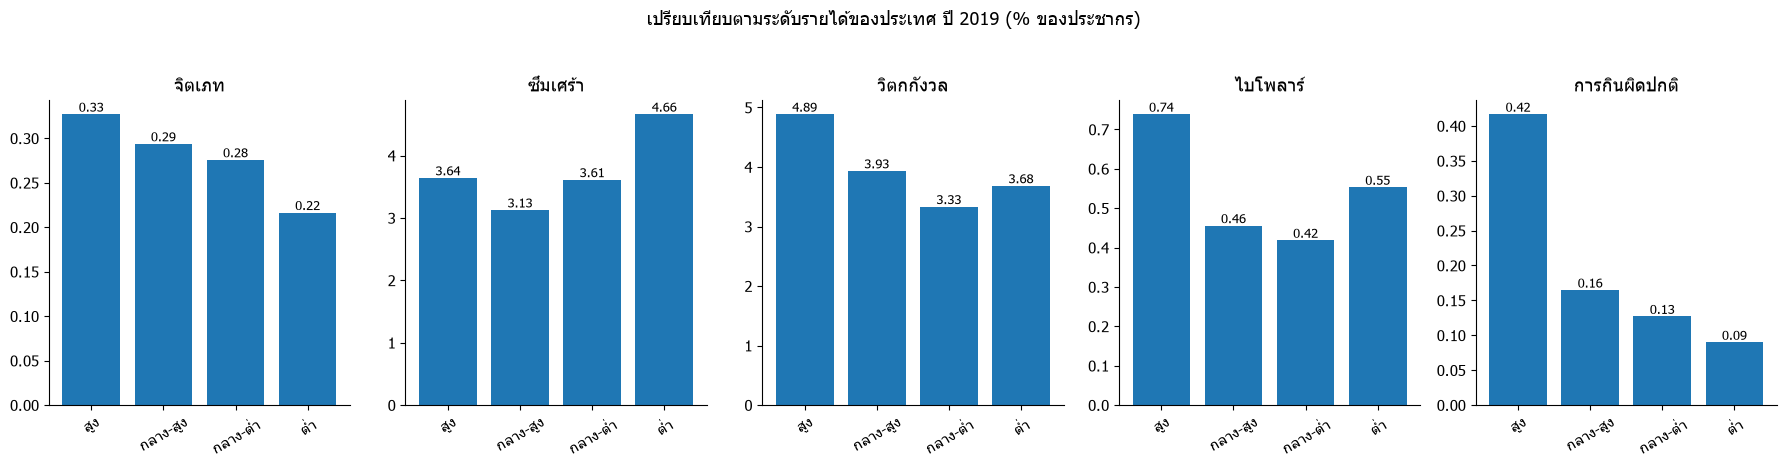

In [19]:
#6. กิมมิค 2: เทียบกลุ่มรายได้ (ใช้แถวกลุ่มรวมที่แยกไว้)
INCOME = ["High-income countries", "Upper-middle-income countries",
          "Lower-middle-income countries", "Low-income countries"]
SHORT = ["สูง", "กลาง-สูง", "กลาง-ต่ำ", "ต่ำ"]

income = (df[(df["Entity"].isin(INCOME)) & (df["Year"] == LAST_YEAR)]
          .set_index("Entity").loc[INCOME, cols].round(4))
income.index = SHORT
income.columns = [DISEASES[c] for c in cols]
print(f"ค่าตามกลุ่มรายได้ ปี {LAST_YEAR} (% ของประชากร)")
print(income.to_string())
income.to_csv(os.path.join(RESULTS, "income_group_comparison.csv"),
              encoding="utf-8-sig")

fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))
for ax, c in zip(axes, cols):
    vals = income[DISEASES[c]]
    bars = ax.bar(SHORT, vals)
    ax.bar_label(bars, fmt="%.2f", fontsize=9)
    ax.set_title(DISEASES[c])
    ax.tick_params(axis="x", labelrotation=30)
fig.suptitle(f"เปรียบเทียบตามระดับรายได้ของประเทศ ปี {LAST_YEAR} (% ของประชากร)",
             y=1.03)
plt.tight_layout()
save_fig("income_group_comparison.png")
plt.show()

In [20]:
#7. กิมมิค 3: แผนที่โลก interactive (plotly) เลือกโรคจากเมนูได้
import plotly.graph_objects as go

iso = latest[latest["Code"].str.len() == 3]   # เฉพาะแถวที่มีรหัสประเทศ ISO3

fig = go.Figure()
for i, c in enumerate(cols):
    fig.add_trace(go.Choropleth(
        locations=iso["Code"], z=iso[c], text=iso["Entity"],
        colorscale="YlOrRd",
        colorbar=dict(title=dict(text="% ของประชากร")),
        hovertemplate="%{text}: %{z:.2f}%<extra></extra>",
        visible=(i == 0)))

buttons = [dict(label=DISEASES[c], method="update",
                args=[{"visible": [j == i for j in range(len(cols))]},
                      {"title": f"{DISEASES[c]}: % ของประชากร ปี {LAST_YEAR}"}])
           for i, c in enumerate(cols)]
fig.update_layout(
    title=f"{DISEASES[cols[0]]}: % ของประชากร ปี {LAST_YEAR}",
    updatemenus=[dict(buttons=buttons, x=0.02, y=1.12, xanchor="left")],
    geo=dict(showframe=False, projection_type="natural earth"),
    margin=dict(l=10, r=10, t=80, b=10))

map_path = os.path.join(RESULTS, "world_map.html")
fig.write_html(map_path)
print("บันทึกแผนที่:", map_path)
fig.show()

บันทึกแผนที่: C:\Users\LENOVO\OneDrive - BUU\Desktop\Results\world_map.html


โรคที่พบสูงสุด: วิตกกังวล
ใช้ข้อมูล 1990-2019: ความชัน=-0.00061/ปี  R²=0.043  ทำนายปี 2029=3.776% [3.715, 3.836]  เทียบปี 2019: -0.10%  -> ยังสรุปทิศทางไม่ได้ (ความชันไม่ต่างจาก 0)
ใช้ข้อมูล 2010-2019 (10 ปีล่าสุด): ความชัน=-0.00439/ปี  R²=0.295  ทำนายปี 2029=3.715% [3.619, 3.811]  เทียบปี 2019: -1.72%  -> ยังสรุปทิศทางไม่ได้ (ความชันไม่ต่างจาก 0)
          โรค  ความชัน(จุด%/ปี)    R²                                      สรุป
       จิตเภท          -0.00007 0.769                             มีแนวโน้มลดลง
     ซึมเศร้า          -0.00639 0.577                             มีแนวโน้มลดลง
    วิตกกังวล          -0.00061 0.043 ยังสรุปทิศทางไม่ได้ (ความชันไม่ต่างจาก 0)
     ไบโพลาร์          -0.00000 0.002 ยังสรุปทิศทางไม่ได้ (ความชันไม่ต่างจาก 0)
การกินผิดปกติ           0.00086 0.880                        มีแนวโน้มเพิ่มขึ้น
บันทึกกราฟ: C:\Users\LENOVO\OneDrive - BUU\Desktop\Results\forecast_top_disease.png


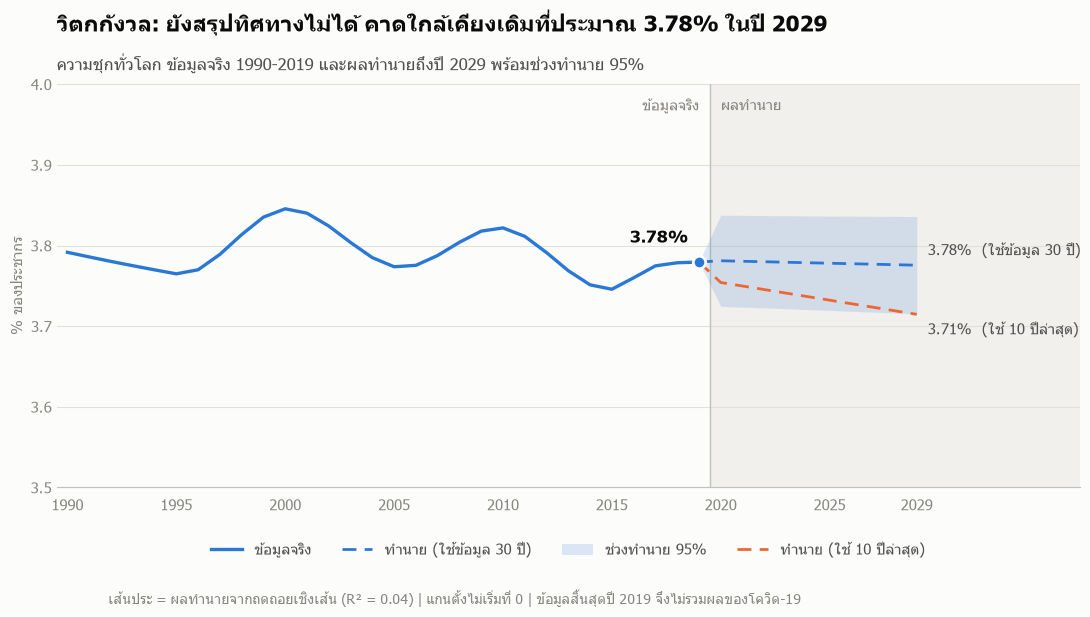

In [21]:
#8. ทำนายแนวโน้ม 10 ปีข้างหน้าของโรคที่พบสูงสุด (ถดถอยเชิงเส้น)
# โรคที่พบสูงสุด = โรคที่ค่าเฉลี่ยรายประเทศสูงสุด (ผลจากข้อ 1)
# ใช้ข้อมูลระดับโลก (แถว World) ทำนายปี LAST_YEAR+1 ถึง LAST_YEAR+10
top_col = countries[cols].mean().idxmax()
top_name = DISEASES[top_col]
T_CRIT = {28: 2.048, 8: 2.306}      # ค่า t ที่ 95% ตามองศาเสรีภาพ (n-2)


def linear_forecast(years, values, future_years):
    n = len(years)
    slope, intercept = np.polyfit(years, values, 1)
    resid = values - (intercept + slope * years)
    s = np.sqrt((resid ** 2).sum() / (n - 2))
    sxx = ((years - years.mean()) ** 2).sum()
    r2 = 1 - (resid ** 2).sum() / ((values - values.mean()) ** 2).sum()
    t = T_CRIT[n - 2]
    pred = intercept + slope * future_years
    margin = t * s * np.sqrt(1 + 1 / n + (future_years - years.mean()) ** 2 / sxx)
    return {"slope": slope, "slope_ci": t * s / np.sqrt(sxx), "r2": r2,
            "pred": pred, "low": pred - margin, "high": pred + margin}


def verdict(r):
    # ถ้าช่วงความเชื่อมั่น 95% ของความชันคร่อมค่า 0 = ยังสรุปทิศทางไม่ได้
    if abs(r["slope"]) <= r["slope_ci"]:
        return "ยังสรุปทิศทางไม่ได้ (ความชันไม่ต่างจาก 0)"
    return "มีแนวโน้มเพิ่มขึ้น" if r["slope"] > 0 else "มีแนวโน้มลดลง"


years_all = world["Year"].values.astype(float)
future = np.arange(LAST_YEAR + 1, LAST_YEAR + 11).astype(float)
y = world[top_col].values

full = linear_forecast(years_all, y, future)                  # ใช้ทั้ง 30 ปี
recent = linear_forecast(years_all[-10:], y[-10:], future)    # ใช้ 10 ปีล่าสุด

print(f"โรคที่พบสูงสุด: {top_name}")
for label, r in [(f"ใช้ข้อมูล {FIRST_YEAR}-{LAST_YEAR}", full),
                 (f"ใช้ข้อมูล {LAST_YEAR - 9}-{LAST_YEAR} (10 ปีล่าสุด)", recent)]:
    chg = (r["pred"][-1] / y[-1] - 1) * 100
    print(f"{label}: ความชัน={r['slope']:.5f}/ปี  R²={r['r2']:.3f}  "
          f"ทำนายปี {int(future[-1])}={r['pred'][-1]:.3f}% "
          f"[{r['low'][-1]:.3f}, {r['high'][-1]:.3f}]  "
          f"เทียบปี {LAST_YEAR}: {chg:+.2f}%  -> {verdict(r)}")

forecast_table = pd.DataFrame({
    "ปี": future.astype(int),
    f"ทำนาย_ทั้ง{len(years_all)}ปี(%)": full["pred"].round(4),
    "ขอบล่าง95%": full["low"].round(4),
    "ขอบบน95%": full["high"].round(4),
    "ทำนาย_10ปีล่าสุด(%)": recent["pred"].round(4),
})
forecast_table.to_csv(os.path.join(RESULTS, "forecast_top_disease.csv"),
                      index=False, encoding="utf-8-sig")

# สรุปทิศทางของทุกโรค (ข้อมูลทั้งหมด) เพื่อเทียบกัน
summary = []
for c in cols:
    r = linear_forecast(years_all, world[c].values, future)
    summary.append({"โรค": DISEASES[c], "ความชัน(จุด%/ปี)": round(r["slope"], 5),
                    "R²": round(r["r2"], 3), "สรุป": verdict(r)})
print(pd.DataFrame(summary).to_string(index=False))

# ---------- กราฟทำนาย (ปรับดีไซน์ให้อ่านง่ายและสวยขึ้น) ----------
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, ZONE = "#e1e0d9", "#c3c2b7", "#f1f0ec"
BLUE, ORANGE = "#2a78d6", "#eb6834"
base = plt.rcParams["font.size"]
DASH = (0, (5, 3))

# หัวข้อสรุปผลอัตโนมัติ (ตามผล verdict ของโมเดลทั้ง 30 ปี)
end_year = int(future[-1])
if verdict(full).startswith("ยังสรุป"):
    headline = (f"{top_name}: ยังสรุปทิศทางไม่ได้ "
                f"คาดใกล้เคียงเดิมที่ประมาณ {full['pred'][-1]:.2f}% ในปี {end_year}")
else:
    headline = (f"{top_name}: {verdict(full)} "
                f"คาดปี {end_year} ≈ {full['pred'][-1]:.2f}%")

fig, ax = plt.subplots(figsize=(11.5, 6.3), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

# โซนทำนาย: พื้นหลังอ่อน + เส้นแบ่งระหว่างข้อมูลจริงกับผลทำนาย
x_split = LAST_YEAR + 0.5
ax.axvspan(x_split, end_year + 7.5, color=ZONE, zorder=0)
ax.axvline(x_split, color=AXIS, linewidth=1, zorder=1)

# ต่อเส้นทำนายจากจุดสุดท้ายของข้อมูลจริง เพื่อไม่ให้เกิดช่องว่าง
fx = np.concatenate(([years_all[-1]], future))
f_pred = np.concatenate(([y[-1]], full["pred"]))
f_low = np.concatenate(([y[-1]], full["low"]))
f_high = np.concatenate(([y[-1]], full["high"]))
r_pred = np.concatenate(([y[-1]], recent["pred"]))

ax.fill_between(fx, f_low, f_high, color=BLUE, alpha=0.16, linewidth=0, zorder=2)
ax.plot(fx, f_pred, color=BLUE, linestyle=DASH, linewidth=2, zorder=3)
ax.plot(fx, r_pred, color=ORANGE, linestyle=DASH, linewidth=2, zorder=3)
ax.plot(years_all, y, color=BLUE, linewidth=2.4, zorder=4)
ax.scatter([years_all[-1]], [y[-1]], s=80, color=BLUE,
           edgecolor=SURFACE, linewidth=2, zorder=5)

# ป้ายค่าที่ปลายเส้น (ตัวอักษรสีหมึกปกติ ไม่ใช้สีของเส้น)
ax.annotate(f"{y[-1]:.2f}%", (years_all[-1], y[-1]), xytext=(-8, 14),
            textcoords="offset points", ha="right", color=INK,
            fontweight="bold", fontsize=base + 1)
ax.annotate(f"{full['pred'][-1]:.2f}%  (ใช้ข้อมูล {len(years_all)} ปี)",
            (end_year, full["pred"][-1]), xytext=(8, 5),
            textcoords="offset points", ha="left", va="bottom",
            color=INK2, fontsize=base)
ax.annotate(f"{recent['pred'][-1]:.2f}%  (ใช้ 10 ปีล่าสุด)",
            (end_year, recent["pred"][-1]), xytext=(8, -5),
            textcoords="offset points", ha="left", va="top",
            color=INK2, fontsize=base)

# ป้ายโซนด้านบนของกราฟ
zone_tf = ax.get_xaxis_transform()
ax.text(x_split - 0.5, 0.965, "ข้อมูลจริง", transform=zone_tf, ha="right",
        va="top", color=MUTED, fontsize=base)
ax.text(x_split + 0.5, 0.965, "ผลทำนาย", transform=zone_tf, ha="left",
        va="top", color=MUTED, fontsize=base)

# แกน: ไม่เริ่มที่ 0 เพื่อให้เห็นรายละเอียด (ระบุไว้ใน footnote)
lo = min(y.min(), full["low"].min(), recent["low"].min())
hi = max(y.max(), full["high"].max(), recent["high"].max())
ax.set_ylim(np.floor((lo - 0.08) * 10) / 10, np.ceil((hi + 0.08) * 10) / 10)
ax.set_xlim(FIRST_YEAR - 0.5, end_year + 7.5)
ax.set_xticks(list(range(FIRST_YEAR, end_year, 5)) + [end_year])
ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.1f"))
ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
ax.tick_params(axis="both", colors=MUTED, length=0, labelsize=base)
ax.tick_params(axis="x", pad=8)
ax.set_ylabel("% ของประชากร", color=MUTED, fontsize=base)

# หัวข้อ (ข้อสรุป) + หัวข้อรอง ชิดซ้าย
ax.set_title(headline, loc="left", fontsize=base + 5, fontweight="bold",
             color=INK, pad=38)
ax.text(0, 1.035, f"ความชุกทั่วโลก ข้อมูลจริง {FIRST_YEAR}-{LAST_YEAR} "
        f"และผลทำนายถึงปี {end_year} พร้อมช่วงทำนาย 95%",
        transform=ax.transAxes, color=INK2, fontsize=base + 1)

# คำอธิบายสัญลักษณ์ (มี 2 เส้นทำนายขึ้นไป จึงต้องมี legend เสมอ)
handles = [
    Line2D([0], [0], color=BLUE, linewidth=2.4, label="ข้อมูลจริง"),
    Line2D([0], [0], color=BLUE, linewidth=2, linestyle=DASH,
           label=f"ทำนาย (ใช้ข้อมูล {len(years_all)} ปี)"),
    Patch(facecolor=BLUE, alpha=0.16, label="ช่วงทำนาย 95%"),
    Line2D([0], [0], color=ORANGE, linewidth=2, linestyle=DASH,
           label="ทำนาย (ใช้ 10 ปีล่าสุด)"),
]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.1),
          ncol=4, frameon=False, labelcolor=INK2, fontsize=base)

fig.text(0.125, 0.015,
         f"เส้นประ = ผลทำนายจากถดถอยเชิงเส้น (R² = {full['r2']:.2f}) | "
         f"แกนตั้งไม่เริ่มที่ 0 | ข้อมูลสิ้นสุดปี {LAST_YEAR} "
         f"จึงไม่รวมผลของโควิด-19",
         color=MUTED, fontsize=base - 1, ha="left")
fig.subplots_adjust(top=0.84, bottom=0.2, left=0.08, right=0.97)

save_fig("forecast_top_disease.png")
plt.show()


บันทึกกราฟ: C:\Users\LENOVO\OneDrive - BUU\Desktop\Results\hist_anxiety.png


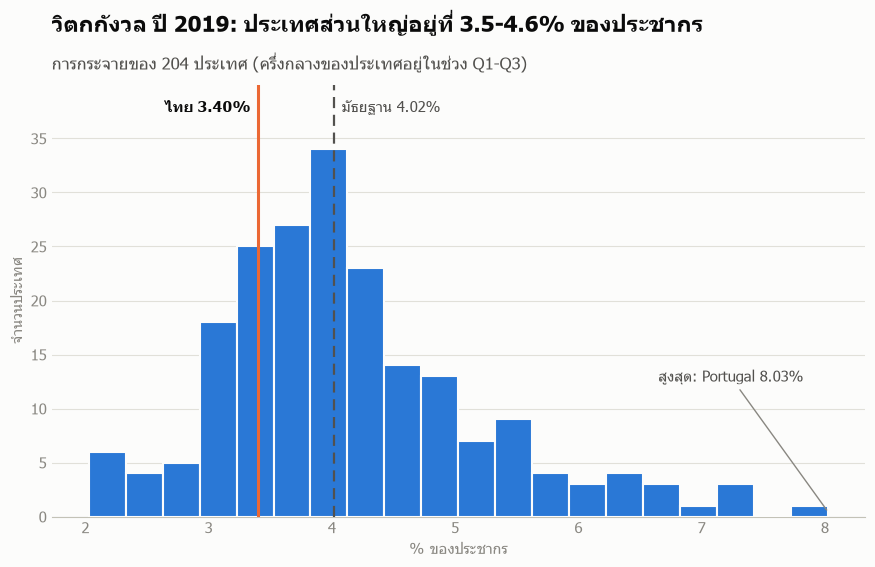

In [22]:
#9. ฮิสโตแกรม: การกระจายของสัดส่วนผู้ป่วยวิตกกังวลรายประเทศ (ข้อ 2)
vals = latest["Anxiety_pct"]
med, q1, q3 = vals.median(), vals.quantile(0.25), vals.quantile(0.75)
top_ent = latest.loc[vals.idxmax(), "Entity"]

fig, ax = plt.subplots(figsize=(10.5, 6), facecolor=SURFACE)
style_axes(ax)
ax.hist(vals, bins=20, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
ymax = ax.get_ylim()[1]
ax.set_ylim(0, ymax * 1.12)

ax.axvline(med, color=INK2, linewidth=1.6, linestyle=DASH, zorder=4)
th_row = latest[latest["Entity"] == "Thailand"]
side = 1
if not th_row.empty:
    th = th_row["Anxiety_pct"].iloc[0]
    side = 1 if th > med else -1
    ax.axvline(th, color=ORANGE, linewidth=2.2, zorder=4)
    ax.text(th + side * 0.06, ymax * 1.08, f"ไทย {th:.2f}%", color=INK,
            fontweight="bold", fontsize=BASE_FONT, va="top",
            ha="left" if side > 0 else "right")
ax.text(med - side * 0.06, ymax * 1.08, f"มัธยฐาน {med:.2f}%", color=INK2,
        fontsize=BASE_FONT, va="top", ha="right" if side > 0 else "left")
ax.annotate(f"สูงสุด: {top_ent} {vals.max():.2f}%", xy=(vals.max(), 0.4),
            xytext=(vals.max() - 0.2, ymax * 0.35), ha="right", color=INK2,
            fontsize=BASE_FONT, arrowprops=dict(arrowstyle="-", color=MUTED))

ax.set_xlabel("% ของประชากร", color=MUTED, fontsize=BASE_FONT)
ax.set_ylabel("จำนวนประเทศ", color=MUTED, fontsize=BASE_FONT)
add_title(ax, f"วิตกกังวล ปี {LAST_YEAR}: ประเทศส่วนใหญ่อยู่ที่ {q1:.1f}-{q3:.1f}% ของประชากร",
          f"การกระจายของ {len(vals)} ประเทศ (ครึ่งกลางของประเทศอยู่ในช่วง Q1-Q3)")
fig.subplots_adjust(top=0.84, bottom=0.12)
save_fig("hist_anxiety.png")
plt.show()

บันทึกกราฟ: C:\Users\LENOVO\OneDrive - BUU\Desktop\Results\scatter_anxiety_depressive.png


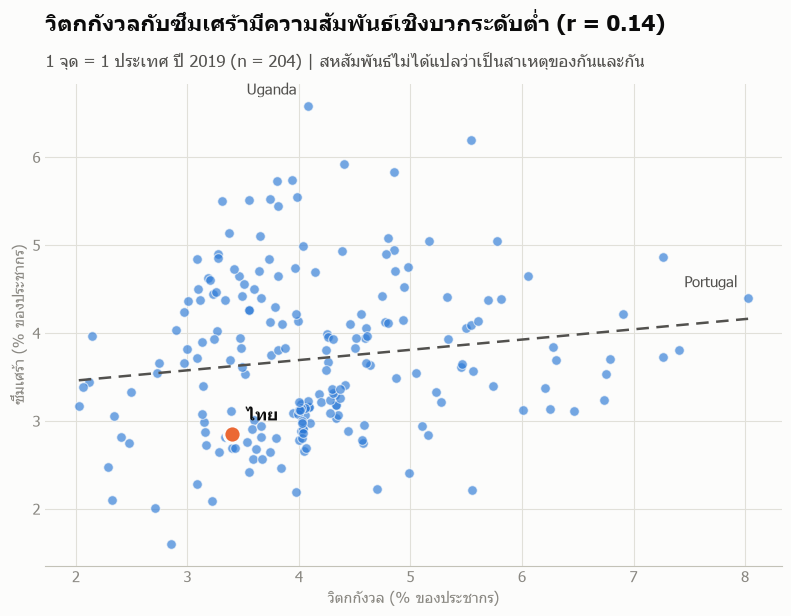

In [23]:
#10. Scatter: วิตกกังวล vs ซึมเศร้า + สหสัมพันธ์เพียร์สัน (r)
x = latest["Anxiety_pct"].values
yv = latest["Depressive_pct"].values
r = np.corrcoef(x, yv)[0, 1]
slope, intercept = np.polyfit(x, yv, 1)
strength = "สูง" if abs(r) >= 0.7 else "ปานกลาง" if abs(r) >= 0.4 else "ต่ำ"
direction = "เชิงบวก" if r > 0 else "เชิงลบ"

fig, ax = plt.subplots(figsize=(9.5, 6.6), facecolor=SURFACE)
style_axes(ax, grid_axis="both")
ax.scatter(x, yv, s=48, color=BLUE, alpha=0.65, edgecolor=SURFACE,
           linewidth=0.8, zorder=3)
xs = np.array([x.min(), x.max()])
ax.plot(xs, intercept + slope * xs, color=INK2, linewidth=1.8,
        linestyle=DASH, zorder=4)

th_row = latest[latest["Entity"] == "Thailand"]
if not th_row.empty:
    tx, ty = th_row["Anxiety_pct"].iloc[0], th_row["Depressive_pct"].iloc[0]
    ax.scatter([tx], [ty], s=150, color=ORANGE, edgecolor=SURFACE,
               linewidth=2, zorder=6)
    ax.annotate("ไทย", (tx, ty), xytext=(10, 10), textcoords="offset points",
                color=INK, fontweight="bold", fontsize=BASE_FONT + 1)
for col, ha_ in [("Anxiety_pct", "right"), ("Depressive_pct", "right")]:
    row = latest.loc[latest[col].idxmax()]
    ax.annotate(f"{row['Entity']}", (row["Anxiety_pct"], row["Depressive_pct"]),
                xytext=(-8, 8), textcoords="offset points", ha=ha_,
                color=INK2, fontsize=BASE_FONT)

ax.set_xlabel("วิตกกังวล (% ของประชากร)", color=MUTED, fontsize=BASE_FONT)
ax.set_ylabel("ซึมเศร้า (% ของประชากร)", color=MUTED, fontsize=BASE_FONT)
add_title(ax, f"วิตกกังวลกับซึมเศร้ามีความสัมพันธ์{direction}ระดับ{strength} (r = {r:.2f})",
          f"1 จุด = 1 ประเทศ ปี {LAST_YEAR} (n = {len(x)}) | "
          "สหสัมพันธ์ไม่ได้แปลว่าเป็นสาเหตุของกันและกัน")
fig.subplots_adjust(top=0.84, bottom=0.11)
save_fig("scatter_anxiety_depressive.png")
plt.show()

บันทึกกราฟ: C:\Users\LENOVO\OneDrive - BUU\Desktop\Results\line_depressive_thailand.png


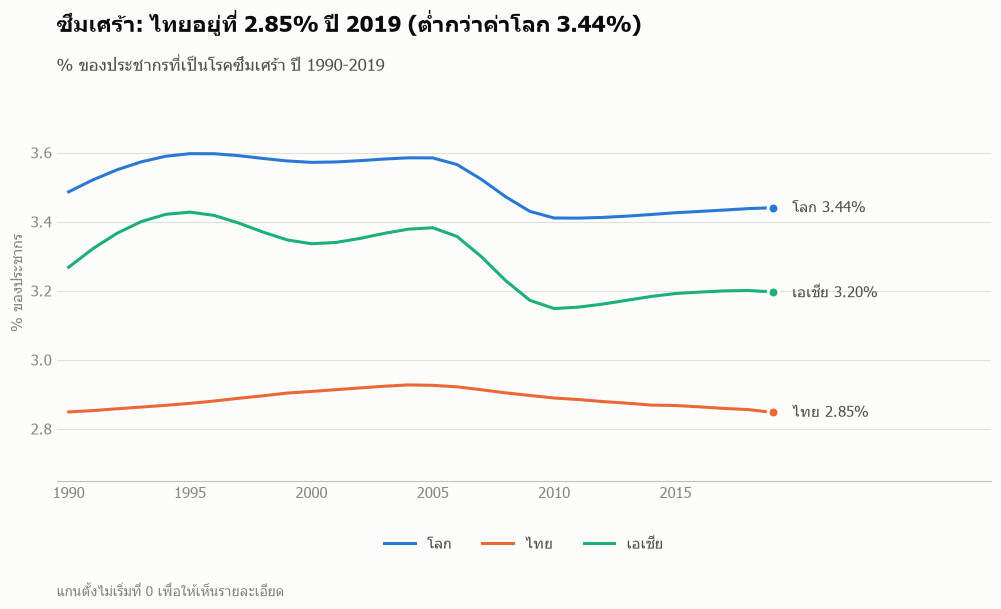

In [24]:
#11. กราฟเส้น: ซึมเศร้าตามปี เทียบ ไทย โลก และเอเชีย
from matplotlib.lines import Line2D

SERIES = [("World", "โลก", BLUE), ("Thailand", "ไทย", ORANGE),
          ("Asia (IHME GBD)", "เอเชีย", AQUA)]
found = []
for ent, label, color in SERIES:
    s = df[df["Entity"] == ent].sort_values("Year")
    if s.empty:
        print("ไม่พบข้อมูล:", ent)
        continue
    found.append((s, label, color))

fig, ax = plt.subplots(figsize=(10.5, 6.2), facecolor=SURFACE)
style_axes(ax)
all_vals = np.concatenate([s["Depressive_pct"].values for s, _, _ in found])
ax.set_ylim(all_vals.min() - 0.2, all_vals.max() + 0.2)
gap = (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.06

for s, label, color in found:
    ax.plot(s["Year"], s["Depressive_pct"], color=color, linewidth=2.2, zorder=3)
    ax.scatter([s["Year"].iloc[-1]], [s["Depressive_pct"].iloc[-1]], s=60,
               color=color, edgecolor=SURFACE, linewidth=2, zorder=4)

# ป้ายชื่อปลายเส้น: เรียงตามค่าและเว้นระยะไม่ให้ทับกัน
ends = sorted([(s["Depressive_pct"].iloc[-1], label) for s, label, _ in found])
pos = []
for i, (v, label) in enumerate(ends):
    pos.append(v if i == 0 else max(v, pos[-1] + gap))
for (v, label), p in zip(ends, pos):
    ax.text(LAST_YEAR + 0.8, p, f"{label} {v:.2f}%", va="center",
            color=INK2, fontsize=BASE_FONT)

ax.set_xlim(FIRST_YEAR - 0.5, LAST_YEAR + 9)
ax.set_xticks(range(FIRST_YEAR, LAST_YEAR + 1, 5))
ax.set_ylabel("% ของประชากร", color=MUTED, fontsize=BASE_FONT)
th_df = df[df["Entity"] == "Thailand"].sort_values("Year")
wd_df = df[df["Entity"] == "World"].sort_values("Year")
if not th_df.empty and not wd_df.empty:
    th_last, wd_last = th_df["Depressive_pct"].iloc[-1], wd_df["Depressive_pct"].iloc[-1]
    word = "ต่ำกว่า" if th_last < wd_last else "สูงกว่า"
    headline = (f"ซึมเศร้า: ไทยอยู่ที่ {th_last:.2f}% ปี {LAST_YEAR} "
                f"({word}ค่าโลก {wd_last:.2f}%)")
else:
    headline = "แนวโน้มโรคซึมเศร้า"
add_title(ax, headline, f"% ของประชากรที่เป็นโรคซึมเศร้า ปี {FIRST_YEAR}-{LAST_YEAR}")

handles = [Line2D([0], [0], color=c, linewidth=2.2, label=l) for _, l, c in found]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.1),
          ncol=len(handles), frameon=False, labelcolor=INK2, fontsize=BASE_FONT)
fig.text(0.08, 0.015, "แกนตั้งไม่เริ่มที่ 0 เพื่อให้เห็นรายละเอียด",
         color=MUTED, fontsize=BASE_FONT - 1)
fig.subplots_adjust(top=0.84, bottom=0.2, left=0.08, right=0.97)
save_fig("line_depressive_thailand.png")
plt.show()

บันทึกกราฟ: C:\Users\LENOVO\OneDrive - BUU\Desktop\Results\heatmap_correlation.png


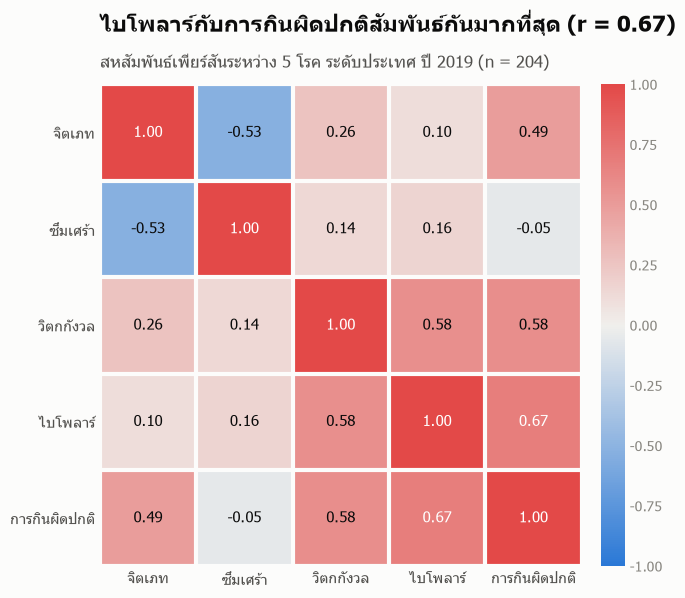

In [25]:
#12. Heatmap สหสัมพันธ์ระหว่างโรคทั้ง 5 (ระดับประเทศ ปีล่าสุด)
from itertools import combinations
from matplotlib.colors import LinearSegmentedColormap

names = [DISEASES[c] for c in cols]
corr = latest[cols].corr()
corr_th = corr.copy()
corr_th.index, corr_th.columns = names, names
corr_th.round(3).to_csv(os.path.join(RESULTS, "correlation_matrix.csv"),
                        encoding="utf-8-sig")

pairs = [(abs(corr.iloc[i, j]), i, j) for i, j in combinations(range(len(cols)), 2)]
_, bi, bj = max(pairs)
cmap = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(8.2, 6.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
mesh = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(names, color=INK2, fontsize=BASE_FONT)
ax.set_yticklabels(names, color=INK2, fontsize=BASE_FONT)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(cols), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(cols), 1), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=3)
ax.tick_params(which="minor", length=0)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if abs(v) > 0.6 else INK, fontsize=BASE_FONT)
cbar = fig.colorbar(mesh, ax=ax, fraction=0.045, pad=0.03)
cbar.outline.set_visible(False)
cbar.ax.tick_params(colors=MUTED, length=0, labelsize=BASE_FONT - 1)
add_title(ax, f"{names[bi]}กับ{names[bj]}สัมพันธ์กันมากที่สุด (r = {corr.iloc[bi, bj]:.2f})",
          f"สหสัมพันธ์เพียร์สันระหว่าง 5 โรค ระดับประเทศ ปี {LAST_YEAR} (n = {len(latest)})")
fig.subplots_adjust(top=0.84)
save_fig("heatmap_correlation.png")
plt.show()

In [26]:
#13. สถิติแยกตามกลุ่ม (groupby): ค่าเฉลี่ยและ SD รายทศวรรษ (ระดับประเทศ)
countries["ทศวรรษ"] = (countries["Year"] // 10 * 10).astype(str) + "s"
by_decade = countries.groupby("ทศวรรษ")[cols].agg(["mean", "std"]).round(3)
stat_th = {"mean": "ค่าเฉลี่ย", "std": "SD"}
by_decade.columns = [f"{DISEASES[c]}_{stat_th[s]}" for c, s in by_decade.columns]
by_decade = by_decade.reset_index()
print(by_decade.to_string(index=False))
by_decade.to_csv(os.path.join(RESULTS, "groupby_decade.csv"),
                 index=False, encoding="utf-8-sig")

ทศวรรษ  จิตเภท_ค่าเฉลี่ย  จิตเภท_SD  ซึมเศร้า_ค่าเฉลี่ย  ซึมเศร้า_SD  วิตกกังวล_ค่าเฉลี่ย  วิตกกังวล_SD  ไบโพลาร์_ค่าเฉลี่ย  ไบโพลาร์_SD  การกินผิดปกติ_ค่าเฉลี่ย  การกินผิดปกติ_SD
 1990s             0.265      0.039               3.814        0.936                4.070         1.030               0.638        0.235                    0.183             0.128
 2000s             0.266      0.040               3.782        0.967                4.087         1.074               0.639        0.236                    0.194             0.141
 2010s             0.267      0.039               3.706        0.919                4.143         1.083               0.640        0.237                    0.208             0.148


In [30]:
from openpyxl.styles import Font

RAW_FILE = os.path.join(BASE, "Data", "raw", "Mental.csv")
EXCEL_FILE = os.path.join(RESULTS, "summary_tables.xlsx")

# ตารางที่ 1: สถิติพรรณนา (หัวคอลัมน์ภาษาไทย)
t1 = desc.reset_index(drop=True).rename(columns={
    "mean": "ค่าเฉลี่ย", "median": "มัธยฐาน", "std": "SD",
    "min": "ต่ำสุด", "max": "สูงสุด", "IQR": "IQR"})
t1 = t1[["โรค", "ค่าเฉลี่ย", "มัธยฐาน", "SD", "ต่ำสุด", "Q1", "Q3",
         "สูงสุด", "IQR", "CV"]].round(3)

# ตารางที่ 2: Top 5 ประเทศของแต่ละโรค (ปี LAST_YEAR) แบบตารางกว้าง
top5 = ranking[(ranking["เกณฑ์"] == f"ปี {LAST_YEAR}") & (ranking["อันดับ"] <= 5)]
t2 = pd.DataFrame({"อันดับ": range(1, 6)})
for c in cols:
    sub = top5[top5["โรค"] == DISEASES[c]].sort_values("อันดับ")
    t2[DISEASES[c]] = [f"{e} ({v:.2f})" for e, v in zip(sub["ประเทศ"], sub["ค่า(%)"])]

# ตารางที่ 3: คุณภาพข้อมูล และค่าผิดปกติ (กฎ 1.5 x IQR เฉพาะประเทศ)
quality = []
if os.path.exists(RAW_FILE):
    raw = pd.read_csv(RAW_FILE)
    quality += [
        ("จำนวนแถวข้อมูลดิบ", len(raw)),
        ("ค่าหายในคอลัมน์ Code (กลุ่มรวม ไม่มีรหัสประเทศ)", int(raw["Code"].isna().sum())),
        ("ค่าหายในคอลัมน์อื่น", int(raw.drop(columns="Code").isna().sum().sum())),
        ("แถวซ้ำ", int(raw.duplicated().sum())),
    ]
else:
    print("ไม่พบไฟล์ดิบ ข้ามส่วนข้อมูลดิบ:", RAW_FILE)
quality += [
    ("จำนวนแถวหลังคลีน", len(df)),
    ("จำนวนประเทศ", countries["Entity"].nunique()),
    ("จำนวนกลุ่มรวม (เช่น World, กลุ่มรายได้)", df[df["Entity_type"] != "Country"]["Entity"].nunique()),
    ("ช่วงปี", f"{FIRST_YEAR}-{LAST_YEAR}"),
]
for c in cols:
    q1, q3 = countries[c].quantile(0.25), countries[c].quantile(0.75)
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n_out = int(((countries[c] < lo) | (countries[c] > hi)).sum())
    quality.append((f"ค่าผิดปกติ (IQR): {DISEASES[c]}",
                    f"{n_out} ({n_out / len(countries) * 100:.2f}%)"))
t3 = pd.DataFrame(quality, columns=["รายการ", "ค่า"])
t3["ค่า"] = t3["ค่า"].astype(str)

sheets = {
    "1_สถิติพรรณนา": t1,
    "2_Top5_ประเทศ": t2,
    "3_คุณภาพข้อมูล": t3,
    "4_แนวโน้ม": trend.reset_index(drop=True),
    "5_กลุ่มรายได้": income.reset_index().rename(columns={"index": "กลุ่มรายได้"}),
    "6_ผลทำนาย": forecast_table,
    "7_ตามทศวรรษ": by_decade,
    "8_สหสัมพันธ์": corr_th.round(3).reset_index().rename(columns={"index": "โรค"}),
    "ภาคผนวก_Top10": ranking,
}

with pd.ExcelWriter(EXCEL_FILE, engine="openpyxl") as writer:
    for name, table in sheets.items():
        table.to_excel(writer, sheet_name=name, index=False)
        ws = writer.sheets[name]
        for col_cells in ws.columns:                       # ปรับความกว้างคอลัมน์
            width = max(len(str(cell.value or "")) for cell in col_cells)
            ws.column_dimensions[col_cells[0].column_letter].width = min(width + 3, 45)
        for cell in ws[1]:                                  # หัวตารางตัวหนา
            cell.font = Font(bold=True)

print("บันทึกไฟล์ Excel:", EXCEL_FILE)
print("ชีตที่ได้:", list(sheets))
display(t1)
display(t2)
display(t3)

บันทึกไฟล์ Excel: C:\Users\LENOVO\OneDrive - BUU\Desktop\Results\summary_tables.xlsx
ชีตที่ได้: ['1_สถิติพรรณนา', '2_Top5_ประเทศ', '3_คุณภาพข้อมูล', '4_แนวโน้ม', '5_กลุ่มรายได้', '6_ผลทำนาย', '7_ตามทศวรรษ', '8_สหสัมพันธ์', 'ภาคผนวก_Top10']


,โรค,ค่าเฉลี่ย,มัธยฐาน,SD,ต่ำสุด,Q1,Q3,สูงสุด,IQR,CV
0,จิตเภท,0.266,0.273,0.039,0.188,0.242,0.286,0.462,0.044,0.148
1,ซึมเศร้า,3.767,3.651,0.942,1.522,3.062,4.372,7.646,1.310,0.250
2,วิตกกังวล,4.100,3.942,1.063,1.880,3.424,4.544,8.625,1.120,0.259
3,ไบโพลาร์,0.639,0.579,0.236,0.182,0.521,0.858,1.507,0.336,0.369
4,การกินผิดปกติ,0.195,0.144,0.139,0.045,0.096,0.244,1.032,0.148,0.714


,อันดับ,จิตเภท,ซึมเศร้า,วิตกกังวล,ไบโพลาร์,การกินผิดปกติ
0,1,United States (0.43),Uganda (6.58),Portugal (8.03),New Zealand (1.51),Australia (1.03)
1,2,Australia (0.39),Palestine (6.20),Brazil (7.41),Australia (1.13),Monaco (0.87)
2,3,New Zealand (0.39),Central African Republic (5.92),Iran (7.27),Brazil (1.11),New Zealand (0.60)
3,4,Greenland (0.38),Greenland (5.84),New Zealand (7.26),United Kingdom (1.09),Spain (0.59)
4,5,Netherlands (0.37),Angola (5.74),Ireland (6.91),Paraguay (1.09),Luxembourg (0.57)


,รายการ,ค่า
0,จำนวนแถวข้อมูลดิบ,6420
1,ค่าหายในคอลัมน์ Code (กลุ่มรวม ไม่มีรหัสประเทศ),270
2,ค่าหายในคอลัมน์อื่น,0
3,แถวซ้ำ,0
4,จำนวนแถวหลังคลีน,6420
5,จำนวนประเทศ,204
6,"จำนวนกลุ่มรวม (เช่น World, กลุ่มรายได้)",10
7,ช่วงปี,1990-2019
8,ค่าผิดปกติ (IQR): จิตเภท,180 (2.94%)
9,ค่าผิดปกติ (IQR): ซึมเศร้า,65 (1.06%)
